# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

In [1]:
import os, time, copy, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import datasets, transforms
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = Path("VinaFood21/VinaFood21")
if Path("/kaggle/input").exists():
    DATA_ROOT = next(p.parent for p in Path("/kaggle/input").rglob("train") if (p.parent / "test").is_dir())
GPU = device.type == "cuda"
BATCH = 32
CACHE_SIZE = 224 if GPU else 160
NUM_WORKERS = min(8, os.cpu_count())
TRAIN_WORKERS = 0 if os.name == "nt" else NUM_WORKERS
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

print("device:", device, "| ảnh cache:", CACHE_SIZE)
print("tìm thấy dữ liệu:", (DATA_ROOT / "train").is_dir(), "-", DATA_ROOT.resolve())

device: cuda | ảnh cache: 224
tìm thấy dữ liệu: True - /kaggle/input/datasets/maket99/dataset/VinaFood21_224


In [2]:
def load_split(split, size):
    ds = datasets.ImageFolder(DATA_ROOT / split, transform=transforms.Compose([
        transforms.Resize((size, size)), transforms.PILToTensor()]))
    xs, ys = zip(*DataLoader(ds, batch_size=256, num_workers=NUM_WORKERS))
    return torch.cat(xs), torch.cat(ys), ds.classes


def resize_uint8(x, size):
    if x.shape[-1] == size:
        return x
    return torch.cat([F.interpolate(x[i:i + 1024].float(), size=(size, size), mode="bilinear",
                                    antialias=True).round().clamp(0, 255).to(torch.uint8)
                      for i in range(0, len(x), 1024)])


SIZED = {}


def sized(size):
    if size not in SIZED:
        SIZED[size] = (resize_uint8(X_TRAIN, size), resize_uint8(X_TEST, size))
    return SIZED[size]


normalize = transforms.Normalize(MEAN, STD)


class CachedImages(Dataset):
    def __init__(self, x, y, transform=None):
        self.x, self.y, self.transform = x, y, transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.x[i] if self.transform is None else self.transform(self.x[i])
        return normalize(x.float() / 255), self.y[i]


def make_aug(img_size):
    return transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ])


def build_loaders(img_size, augment=True, val_ratio=0.1):
    x_train, x_test = sized(img_size)
    idx = torch.randperm(len(Y_TRAIN), generator=torch.Generator().manual_seed(SEED))
    n_val = int(len(idx) * val_ratio)
    tr, va = idx[n_val:], idx[:n_val]
    train_ds = CachedImages(x_train[tr], Y_TRAIN[tr], make_aug(img_size) if augment else None)
    val_ds = CachedImages(x_train[va], Y_TRAIN[va])
    test_ds = CachedImages(x_test, Y_TEST)
    return (DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=TRAIN_WORKERS),
            DataLoader(val_ds, batch_size=256), DataLoader(test_ds, batch_size=256))


def denorm(t):
    return (t.cpu().permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)


t0 = time.time()
X_TRAIN, Y_TRAIN, CLASSES = load_split("train", CACHE_SIZE)
X_TEST, Y_TEST, test_classes = load_split("test", CACHE_SIZE)
assert test_classes == CLASSES
print(f"đọc {len(Y_TRAIN):,} ảnh train và {len(Y_TEST):,} ảnh test vào RAM trong {time.time() - t0:.0f}s")

loaders64 = build_loaders(64)
print("số lớp:", len(CLASSES))
print("train / val / test:", *(len(dl.dataset) for dl in loaders64))
xb, yb = next(iter(loaders64[0]))
print("một batch:", tuple(xb.shape), tuple(yb.shape))

đọc 10,044 ảnh train và 6,682 ảnh test vào RAM trong 373s
số lớp: 21
train / val / test: 9040 1004 6682
một batch: (32, 3, 64, 64) (32,)


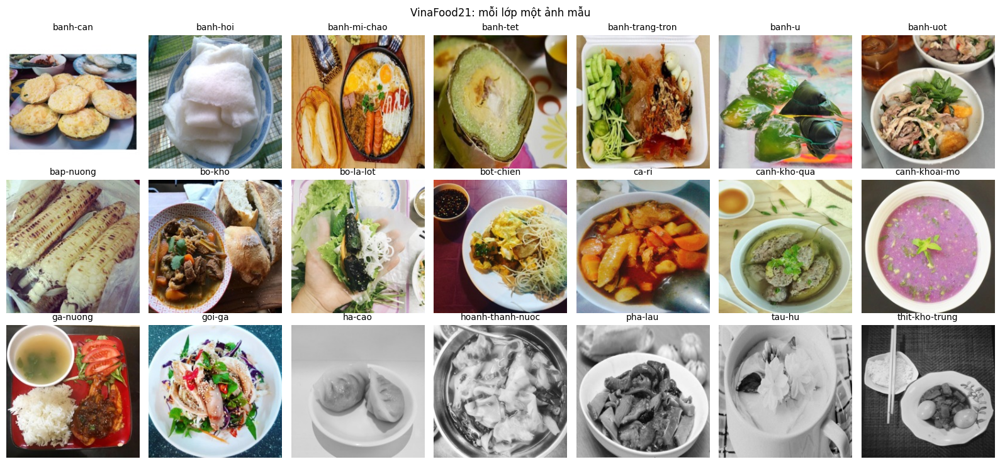

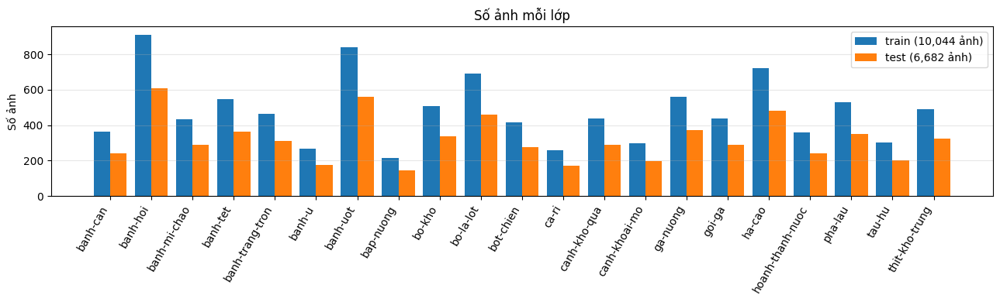

In [3]:
raw_train = datasets.ImageFolder(DATA_ROOT / "train")
raw_test = datasets.ImageFolder(DATA_ROOT / "test")
first = {}
for path, y in raw_train.samples:
    first.setdefault(y, path)

fig, axes = plt.subplots(3, 7, figsize=(16, 7.5))
for ax, (y, path) in zip(axes.ravel(), sorted(first.items())):
    ax.imshow(raw_train.loader(path)); ax.set_title(CLASSES[y], fontsize=10); ax.axis("off")
plt.suptitle("VinaFood21: mỗi lớp một ảnh mẫu"); plt.tight_layout(); plt.show()

n_train = np.bincount(raw_train.targets, minlength=len(CLASSES))
n_test = np.bincount(raw_test.targets, minlength=len(CLASSES))
x = np.arange(len(CLASSES))
plt.figure(figsize=(13, 4))
plt.bar(x - 0.2, n_train, 0.4, label=f"train ({n_train.sum():,} ảnh)")
plt.bar(x + 0.2, n_test, 0.4, label=f"test ({n_test.sum():,} ảnh)")
plt.xticks(x, CLASSES, rotation=60, ha="right"); plt.ylabel("Số ảnh")
plt.title("Số ảnh mỗi lớp"); plt.legend(); plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

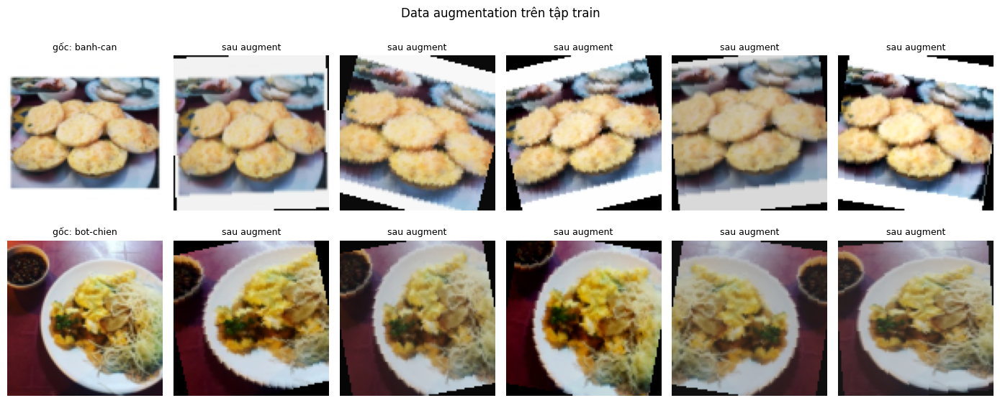

In [4]:
x96, _ = sized(96)
aug = make_aug(96)
fig, axes = plt.subplots(2, 6, figsize=(14, 6))
for row, y in zip(axes, (0, len(CLASSES) // 2)):
    i = int((Y_TRAIN == y).nonzero()[0])
    row[0].imshow(x96[i].permute(1, 2, 0)); row[0].set_title(f"gốc: {CLASSES[y]}", fontsize=9)
    for ax in row[1:]:
        ax.imshow(aug(x96[i]).permute(1, 2, 0)); ax.set_title("sau augment", fontsize=9)
    for ax in row:
        ax.axis("off")
plt.suptitle("Data augmentation trên tập train"); plt.tight_layout(); plt.show()

In [5]:
def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running, y_true, y_pred = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += logits.argmax(1).cpu().tolist()
    return running / len(y_true), np.array(y_true), np.array(y_pred)


def fit(model, loaders, epochs, lr=1e-3):
    train_dl, val_dl, _ = loaders
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "time")}
    best_f1, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer)
        va_loss, yt, yp = evaluate(model, val_dl, criterion)
        va_acc, va_f1 = accuracy_score(yt, yp), f1_score(yt, yp, average="macro")
        for k, v in zip(hist, (tr_loss, tr_acc, va_loss, va_acc, va_f1, time.time() - t0)):
            hist[k].append(v)
        mark = ""
        if va_f1 > best_f1:
            best_f1, best_state, mark = va_f1, copy.deepcopy(model.state_dict()), "  *"
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}   val {va_loss:.4f}/{va_acc:.4f}"
              f"  F1 {va_f1:.4f}  {hist['time'][-1]:.0f}s{mark}")
    model.load_state_dict(best_state)
    print(f"Dùng trọng số ở epoch có val macro-F1 cao nhất: {best_f1:.4f}")
    return hist


@torch.no_grad()
def show_predictions(model, ds, name, n=12):
    model.eval()
    idx = random.Random(SEED).sample(range(len(ds)), n)
    xs = torch.stack([ds[i][0] for i in idx])
    ys = [int(ds[i][1]) for i in idx]
    preds = model(xs.to(device)).argmax(1).cpu().tolist()
    fig, axes = plt.subplots(2, n // 2, figsize=(2.3 * n // 2, 6.4))
    for ax, x, y, p in zip(axes.ravel(), xs, ys, preds):
        ax.imshow(denorm(x)); ax.axis("off")
        ax.set_title(f"thật: {CLASSES[y]}\nđoán: {CLASSES[p]}", fontsize=8,
                     color="green" if y == p else "red")
    plt.suptitle(f"Dự đoán trên ảnh test: {name}"); plt.tight_layout(); plt.show()


RESULTS, PER_CLASS_F1 = {}, {}


def report(model, hist, loaders, name, preview=None):
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    split = ep[np.argmin(hist["val_loss"])]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    ax1.plot(ep, hist["train_loss"], "o-", label="train loss")
    ax1.plot(ep, hist["val_loss"], "s-", label="val loss")
    ax1.axvline(split, ls="--", c="gray", label=f"val loss thấp nhất (epoch {split})")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy"); ax1.set_title(f"{name}: loss")
    ax2.plot(ep, hist["train_acc"], "o-", label="train accuracy")
    ax2.plot(ep, hist["val_acc"], "s-", label="val accuracy")
    ax2.plot(ep, hist["val_f1"], "^-", label="val macro-F1")
    ax2.set_xlabel("epoch"); ax2.set_title(f"{name}: accuracy / F1")
    for ax in (ax1, ax2):
        ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

    _, y_true, y_pred = evaluate(model, loaders[2], nn.CrossEntropyLoss())
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    RESULTS[name] = {"Tham số": n_params(model), "Tham số học": n_params(model, True),
                     "Giây/epoch": float(np.mean(hist["time"])),
                     "Accuracy": acc, "Precision": p, "Recall": r, "F1-macro": f1}
    PER_CLASS_F1[name] = f1_score(y_true, y_pred, average=None,
                                  labels=range(len(CLASSES)), zero_division=0)
    print(f"{name} trên tập test")
    print(f"Accuracy       : {acc:.4f}")
    print(f"Precision macro: {p:.4f}")
    print(f"Recall macro   : {r:.4f}")
    print(f"F1 macro       : {f1:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=90)
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    for i, j in zip(*np.nonzero(cm)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("Nhãn dự đoán"); ax.set_ylabel("Nhãn thật")
    ax.set_title(f"Ma trận nhầm lẫn: {name}")
    fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

    off = cm.copy(); np.fill_diagonal(off, 0)
    print("5 cặp (thật -> đoán) nhầm nhiều nhất:")
    for idx in off.ravel().argsort()[::-1][:5]:
        t, pr = divmod(idx, len(CLASSES))
        print(f"  {CLASSES[t]} -> {CLASSES[pr]}: {off[t, pr]} ảnh")

    show_predictions(*(preview or (model, loaders[2].dataset)), name)

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

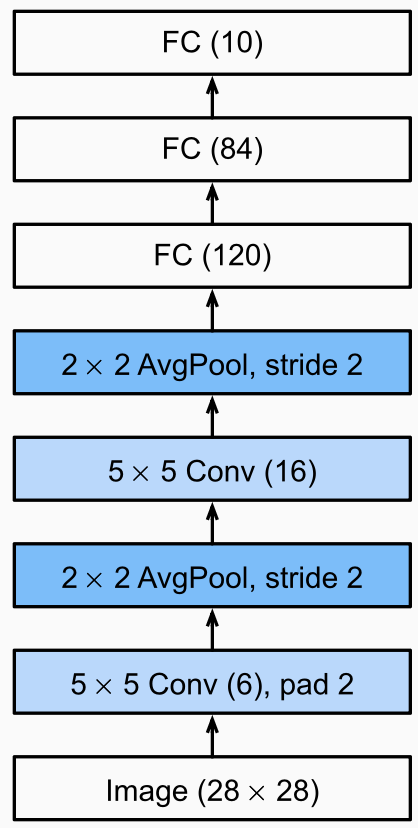

In [6]:
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)
        with torch.no_grad():
            n_flat = self.s4(self.c3(self.s2(self.c1(torch.zeros(1, in_ch, img, img))))).numel()
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)


lenet = LeNet5(num_classes=len(CLASSES))
x = torch.zeros(1, 3, 64, 64)
print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name in ("c1", "s2", "c3", "s4", "flatten", "f5", "f6", "out"):
    layer = nn.Flatten() if name == "flatten" else getattr(lenet, name)
    x = layer(x)
    print(f"{name.upper():<10}{'x'.join(map(str, x.shape[1:])):<16}{n_params(layer):>12,}")
print(f"{'TỔNG':<10}{'':<16}{n_params(lenet):>12,}")

layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
FLATTEN   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


epoch  1  train 2.7834/0.1582   val 2.5633/0.2171  F1 0.1276  10s  *
epoch  2  train 2.5604/0.2194   val 2.4536/0.2371  F1 0.1661  8s  *
epoch  3  train 2.4926/0.2406   val 2.3664/0.2669  F1 0.1956  8s  *
epoch  4  train 2.4181/0.2617   val 2.3092/0.2849  F1 0.2484  8s  *
epoch  5  train 2.3508/0.2748   val 2.2399/0.3048  F1 0.2510  8s  *
epoch  6  train 2.3068/0.2936   val 2.2423/0.3157  F1 0.2727  8s  *
epoch  7  train 2.2574/0.3040   val 2.1956/0.3108  F1 0.2633  8s
epoch  8  train 2.2154/0.3184   val 2.2770/0.3396  F1 0.2870  8s  *
epoch  9  train 2.1826/0.3268   val 2.1879/0.3347  F1 0.2709  8s
epoch 10  train 2.1407/0.3414   val 2.2041/0.3357  F1 0.2860  8s
epoch 11  train 2.1085/0.3515   val 2.1246/0.3466  F1 0.3077  8s  *
epoch 12  train 2.0776/0.3572   val 2.1651/0.3347  F1 0.3100  8s  *
epoch 13  train 2.0491/0.3629   val 2.1139/0.3635  F1 0.3306  8s  *
epoch 14  train 2.0403/0.3669   val 2.0673/0.3695  F1 0.3344  8s  *
epoch 15  train 2.0150/0.3753   val 2.0902/0.3675  F1 0.

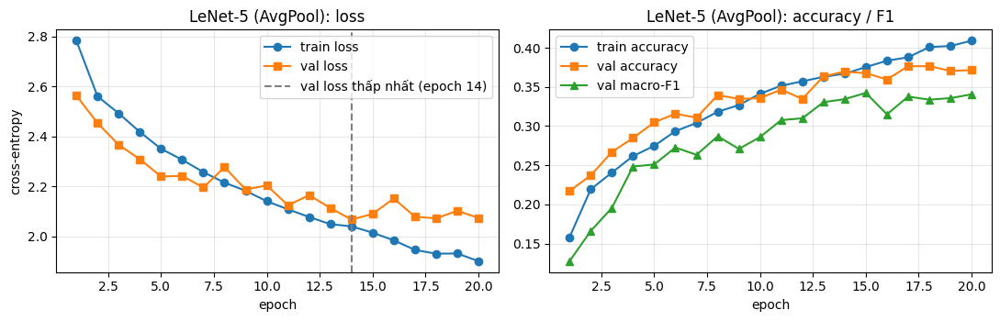

LeNet-5 (AvgPool) trên tập test
Accuracy       : 0.2986
Precision macro: 0.3011
Recall macro   : 0.2805
F1 macro       : 0.2749

                  precision    recall  f1-score   support

        banh-can     0.2105    0.0830    0.1190       241
        banh-hoi     0.2750    0.6079    0.3787       607
    banh-mi-chao     0.3529    0.2907    0.3188       289
        banh-tet     0.3084    0.1813    0.2284       364
 banh-trang-tron     0.1909    0.1489    0.1673       309
          banh-u     0.2192    0.0909    0.1285       176
        banh-uot     0.3669    0.2018    0.2604       560
       bap-nuong     0.1977    0.1189    0.1485       143
          bo-kho     0.2422    0.2515    0.2467       338
       bo-la-lot     0.4510    0.5524    0.4966       458
       bot-chien     0.1621    0.2355    0.1920       276
           ca-ri     0.2727    0.1053    0.1519       171
    canh-kho-qua     0.4174    0.5138    0.4606       290
   canh-khoai-mo     0.6746    0.7121    0.6929       198


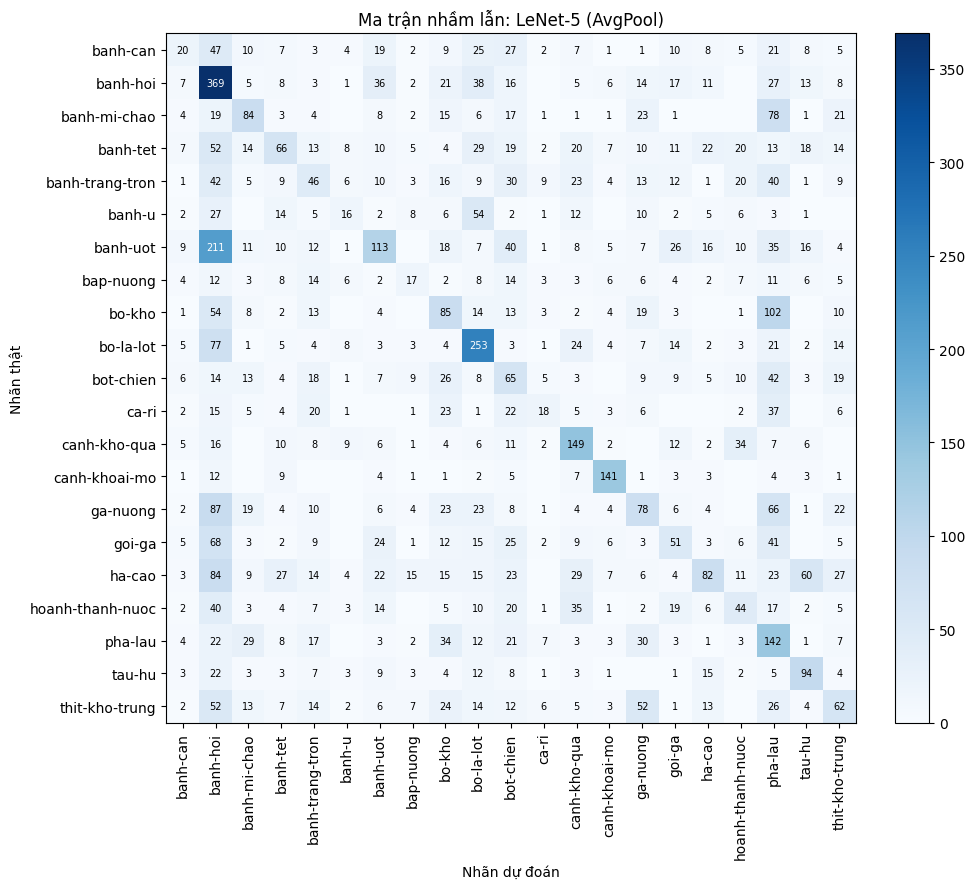

5 cặp (thật -> đoán) nhầm nhiều nhất:
  banh-uot -> banh-hoi: 211 ảnh
  bo-kho -> pha-lau: 102 ảnh
  ga-nuong -> banh-hoi: 87 ảnh
  ha-cao -> banh-hoi: 84 ảnh
  banh-mi-chao -> pha-lau: 78 ảnh


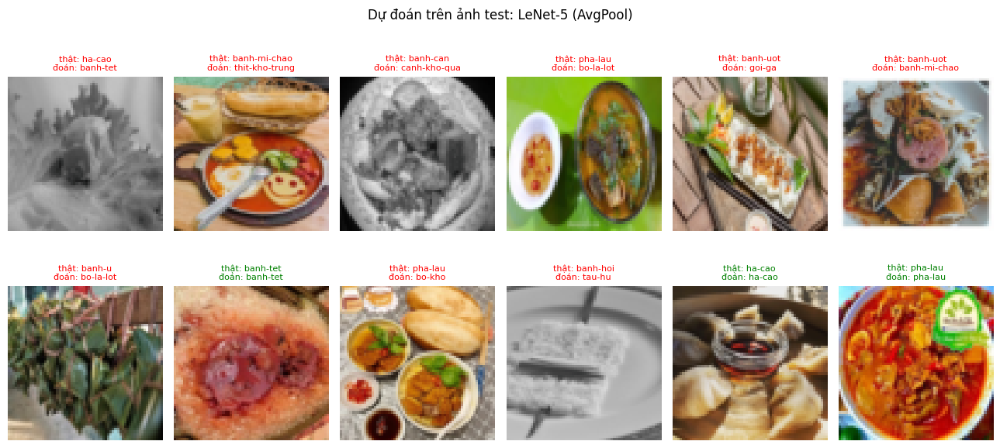

In [7]:
EPOCHS_LENET = 20

set_seed()
lenet_avg = LeNet5(num_classes=len(CLASSES), pool="avg")
hist_avg = fit(lenet_avg, loaders64, epochs=EPOCHS_LENET)
report(lenet_avg, hist_avg, loaders64, "LeNet-5 (AvgPool)")

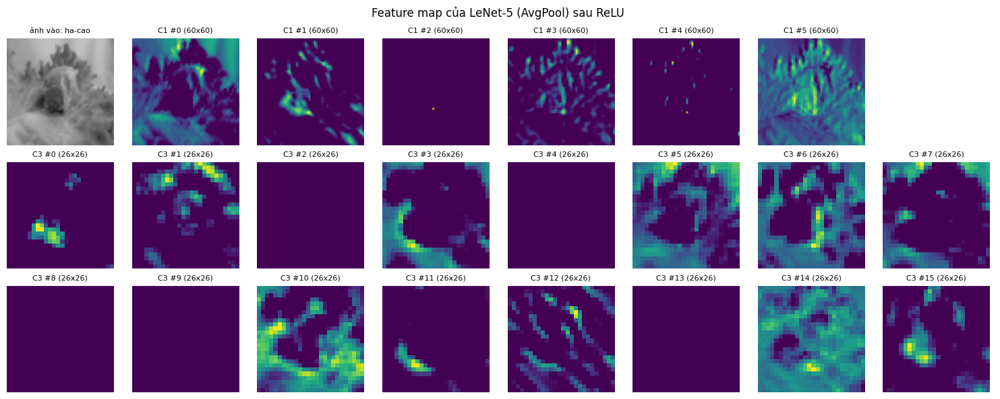

In [8]:
test64 = loaders64[2].dataset
img, label = test64[random.Random(SEED).randrange(len(test64))]
lenet_avg.eval()
with torch.no_grad():
    c1 = torch.relu(lenet_avg.c1(img[None].to(device)))
    c3 = torch.relu(lenet_avg.c3(lenet_avg.s2(c1)))[0].cpu()
    c1 = c1[0].cpu()

fig, axes = plt.subplots(3, 8, figsize=(15, 6))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].imshow(denorm(img)); axes[0, 0].set_title(f"ảnh vào: {CLASSES[label]}", fontsize=8)
for i in range(6):
    axes[0, i + 1].imshow(c1[i], cmap="viridis"); axes[0, i + 1].set_title(f"C1 #{i} (60x60)", fontsize=8)
for i in range(16):
    ax = axes[1 + i // 8, i % 8]
    ax.imshow(c3[i], cmap="viridis"); ax.set_title(f"C3 #{i} (26x26)", fontsize=8)
plt.suptitle("Feature map của LeNet-5 (AvgPool) sau ReLU"); plt.tight_layout(); plt.show()

epoch  1  train 2.7822/0.1594   val 2.5528/0.2112  F1 0.1339  8s  *
epoch  2  train 2.5372/0.2222   val 2.3846/0.2500  F1 0.1784  8s  *
epoch  3  train 2.4515/0.2508   val 2.2905/0.2958  F1 0.2322  8s  *
epoch  4  train 2.3658/0.2729   val 2.2820/0.2898  F1 0.2382  8s  *
epoch  5  train 2.2835/0.2991   val 2.1755/0.3157  F1 0.2624  8s  *
epoch  6  train 2.2419/0.3108   val 2.1576/0.3506  F1 0.3082  8s  *
epoch  7  train 2.1832/0.3271   val 2.1542/0.3426  F1 0.3040  8s
epoch  8  train 2.1524/0.3316   val 2.1123/0.3665  F1 0.3102  8s  *
epoch  9  train 2.1119/0.3438   val 2.1367/0.3526  F1 0.2989  8s
epoch 10  train 2.0679/0.3631   val 2.0822/0.3566  F1 0.3188  8s  *
epoch 11  train 2.0355/0.3713   val 2.0304/0.3755  F1 0.3404  8s  *
epoch 12  train 2.0204/0.3785   val 2.0060/0.3865  F1 0.3603  8s  *
epoch 13  train 1.9930/0.3777   val 2.0274/0.4064  F1 0.3717  8s  *
epoch 14  train 1.9761/0.3905   val 2.0538/0.3944  F1 0.3676  8s
epoch 15  train 1.9564/0.3928   val 2.0560/0.3645  F1 0.3

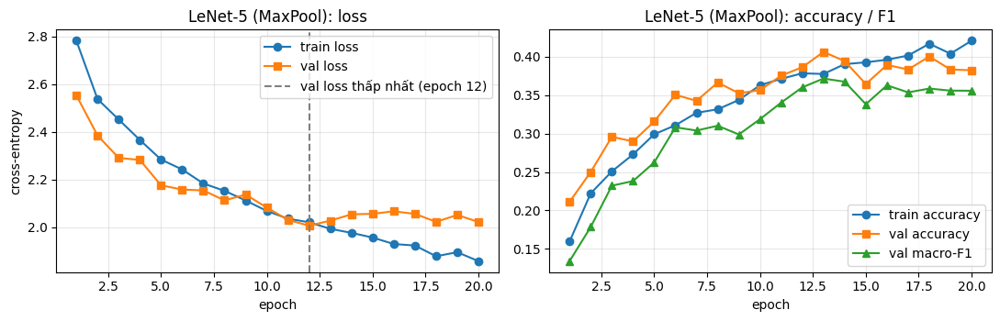

LeNet-5 (MaxPool) trên tập test
Accuracy       : 0.3120
Precision macro: 0.3247
Recall macro   : 0.2853
F1 macro       : 0.2863

                  precision    recall  f1-score   support

        banh-can     0.1885    0.0954    0.1267       241
        banh-hoi     0.2357    0.5832    0.3357       607
    banh-mi-chao     0.3502    0.3841    0.3663       289
        banh-tet     0.3829    0.2335    0.2901       364
 banh-trang-tron     0.2254    0.1036    0.1419       309
          banh-u     0.2840    0.1307    0.1790       176
        banh-uot     0.2500    0.2518    0.2509       560
       bap-nuong     0.1515    0.0699    0.0957       143
          bo-kho     0.2145    0.3846    0.2754       338
       bo-la-lot     0.4334    0.7031    0.5362       458
       bot-chien     0.2795    0.1630    0.2059       276
           ca-ri     0.2500    0.0702    0.1096       171
    canh-kho-qua     0.5548    0.5931    0.5733       290
   canh-khoai-mo     0.8500    0.6869    0.7598       198


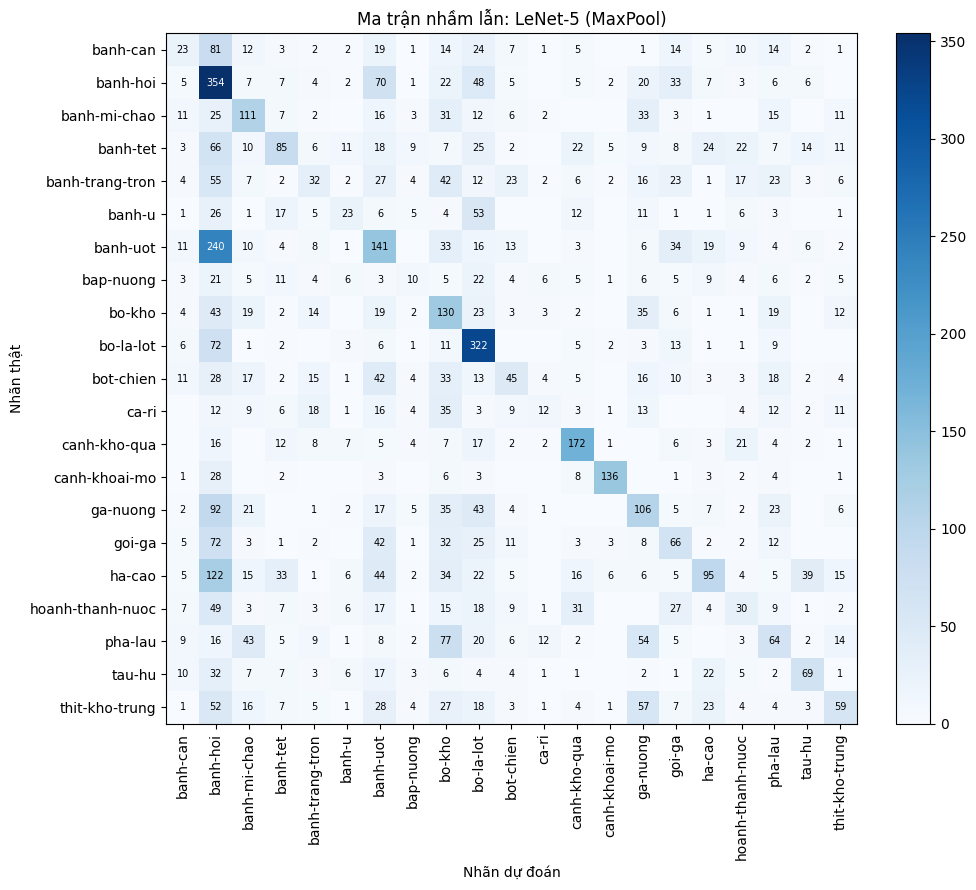

5 cặp (thật -> đoán) nhầm nhiều nhất:
  banh-uot -> banh-hoi: 240 ảnh
  ha-cao -> banh-hoi: 122 ảnh
  ga-nuong -> banh-hoi: 92 ảnh
  banh-can -> banh-hoi: 81 ảnh
  pha-lau -> bo-kho: 77 ảnh


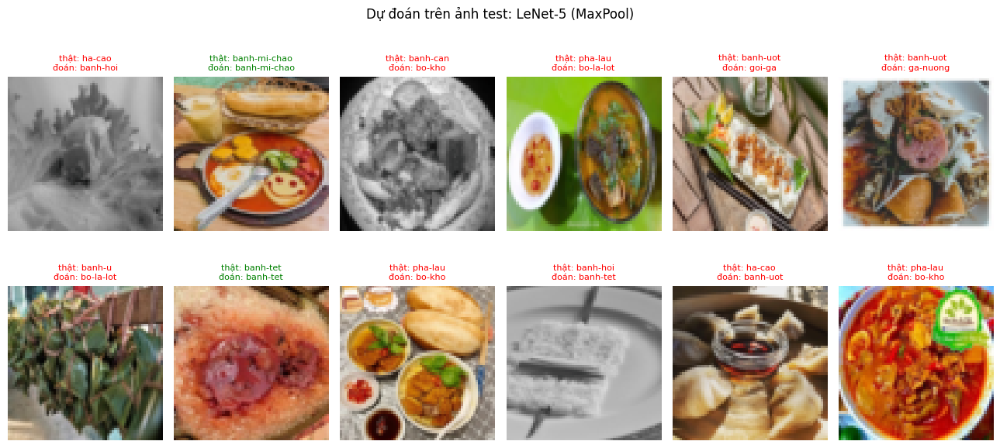


macro-F1 AvgPool: 0.2749
macro-F1 MaxPool: 0.2863


In [9]:
set_seed()
lenet_max = LeNet5(num_classes=len(CLASSES), pool="max")
hist_max = fit(lenet_max, loaders64, epochs=EPOCHS_LENET)
report(lenet_max, hist_max, loaders64, "LeNet-5 (MaxPool)")

print(f"\nmacro-F1 AvgPool: {RESULTS['LeNet-5 (AvgPool)']['F1-macro']:.4f}")
print(f"macro-F1 MaxPool: {RESULTS['LeNet-5 (MaxPool)']['F1-macro']:.4f}")

**Nhận xét Bài 1.**
- LeNet-5 có 339,421 tham số, trong đó 95.6% nằm ở lớp F5. Trên 21 lớp, mô hình chỉ đạt accuracy ≈ 0.30 và F1-macro 0.27–0.29.
- MaxPool nhỉnh hơn AvgPool (F1-macro 0.2863 so với 0.2749), vì MaxPool giữ lại phản hồi mạnh nhất (cạnh, vân) thay vì lấy trung bình làm mờ.
- Mô hình quá nông so với ảnh món ăn màu 64×64, nên dự đoán dồn về lớp có nhiều ảnh nhất là `banh-hoi`: cả 5 cặp nhầm nhiều nhất đều có dạng "→ banh-hoi" (riêng `banh-uot → banh-hoi` là 211–240 ảnh).
- Lớp dễ nhất là `canh-khoai-mo` (F1 0.69–0.76, màu tím rất đặc trưng). Các lớp khó nhất là `banh-can`, `bap-nuong`, `banh-u` (F1 < 0.15).
- Sau 20 epoch, train loss và val loss vẫn sát nhau và còn giảm, nghĩa là mô hình đang underfit chứ chưa overfit.

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

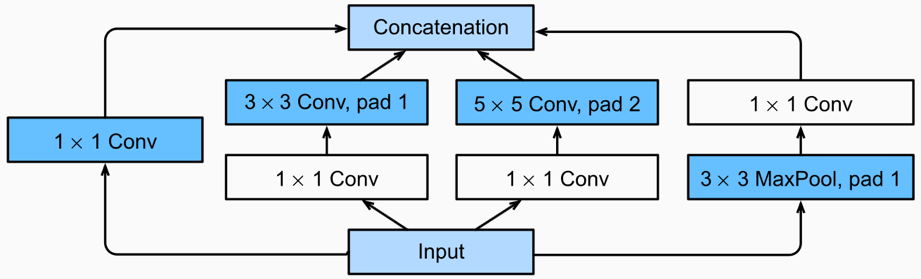

**GoogLeNet (Multi-branch Network)**

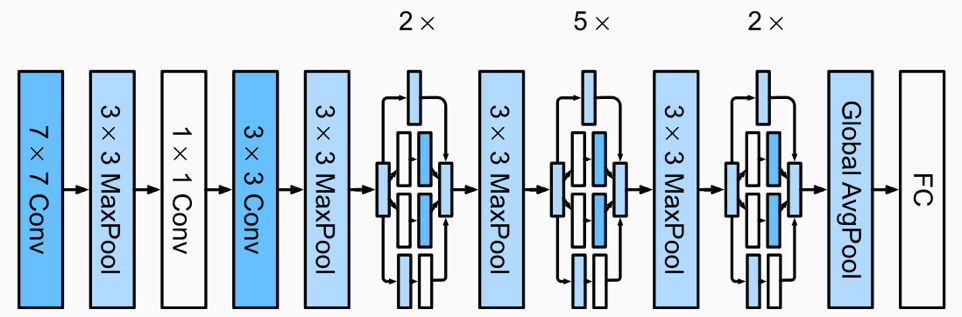

In [10]:
def conv_bn(in_ch, out_ch, k, s=1, p=0):
    return nn.Sequential(nn.Conv2d(in_ch, out_ch, k, s, p, bias=False),
                         nn.BatchNorm2d(out_ch), nn.ReLU())


class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = conv_bn(in_ch, f1, 1)
        self.b2 = nn.Sequential(conv_bn(in_ch, f3r, 1), conv_bn(f3r, f3, 3, p=1))
        self.b3 = nn.Sequential(conv_bn(in_ch, f5r, 1), conv_bn(f5r, f5, 5, p=2))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), conv_bn(in_ch, fp, 1))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)


INCEPTION_CFG = {
    "inception3a": (192, 64, 96, 128, 16, 32, 32),
    "inception3b": (256, 128, 128, 192, 32, 96, 64),
    "inception4a": (480, 192, 96, 208, 16, 48, 64),
}


class GoogLeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            conv_bn(3, 64, 7, s=2, p=3), nn.MaxPool2d(3, 2, padding=1),
            conv_bn(64, 64, 1), conv_bn(64, 192, 3, p=1), nn.MaxPool2d(3, 2, padding=1))
        self.inception3a = InceptionBlock(*INCEPTION_CFG["inception3a"])
        self.inception3b = InceptionBlock(*INCEPTION_CFG["inception3b"])
        self.pool3 = nn.MaxPool2d(3, 2, padding=1)
        self.inception4a = InceptionBlock(*INCEPTION_CFG["inception4a"])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                  nn.Dropout(0.4), nn.Linear(512, num_classes))

    def forward(self, x):
        x = self.stem(x)
        x = self.inception3b(self.inception3a(x))
        x = self.inception4a(self.pool3(x))
        return self.head(x)


gn = GoogLeNet(len(CLASSES)).eval()
x = gn.stem(torch.zeros(1, 3, 64, 64))
print(f"{'stem':<12} -> {tuple(x.shape[1:])}")
for name in ("inception3a", "inception3b", "pool3", "inception4a"):
    layer = getattr(gn, name)
    x = layer(x)
    if name not in INCEPTION_CFG:
        print(f"{name:<12} -> {tuple(x.shape[1:])}")
        continue
    _, f1, _, f3, _, f5, fp = INCEPTION_CFG[name]
    print(f"{name:<12} -> {tuple(x.shape[1:])} | tính tay: {f1} + {f3} + {f5} + {fp}"
          f" = {f1 + f3 + f5 + fp} | {n_params(layer):,} tham số")
    assert x.shape[1] == f1 + f3 + f5 + fp
print(f"\nTổng tham số GoogLeNet: {n_params(gn):,}")

stem         -> (192, 8, 8)
inception3a  -> (256, 8, 8) | tính tay: 64 + 128 + 32 + 32 = 256 | 164,064 tham số
inception3b  -> (480, 8, 8) | tính tay: 128 + 192 + 96 + 64 = 480 | 389,376 tham số
pool3        -> (480, 4, 4)
inception4a  -> (512, 4, 4) | tính tay: 192 + 208 + 48 + 64 = 512 | 376,800 tham số

Tổng tham số GoogLeNet: 1,065,749


epoch  1  train 2.6253/0.2014   val 2.3940/0.2440  F1 0.1777  10s  *
epoch  2  train 2.3291/0.2821   val 2.2156/0.3127  F1 0.2585  9s  *
epoch  3  train 2.1423/0.3419   val 2.2564/0.3078  F1 0.2663  9s  *
epoch  4  train 2.0149/0.3708   val 1.8459/0.4303  F1 0.3918  9s  *
epoch  5  train 1.8850/0.4148   val 1.9058/0.4303  F1 0.3903  9s
epoch  6  train 1.8029/0.4364   val 1.6556/0.4761  F1 0.4353  9s  *
epoch  7  train 1.7243/0.4576   val 1.6814/0.4791  F1 0.4492  9s  *
epoch  8  train 1.6618/0.4748   val 1.6473/0.4960  F1 0.4512  9s  *
epoch  9  train 1.5919/0.5027   val 1.5441/0.5070  F1 0.4896  9s  *
epoch 10  train 1.5350/0.5198   val 1.5435/0.5090  F1 0.4799  9s
epoch 11  train 1.4933/0.5257   val 1.4398/0.5349  F1 0.5018  9s  *
epoch 12  train 1.4398/0.5393   val 1.4845/0.5498  F1 0.5164  9s  *
epoch 13  train 1.3971/0.5541   val 1.4464/0.5598  F1 0.5218  9s  *
epoch 14  train 1.3499/0.5725   val 1.4478/0.5468  F1 0.5079  9s
epoch 15  train 1.3016/0.5829   val 1.4132/0.5608  F1 0.

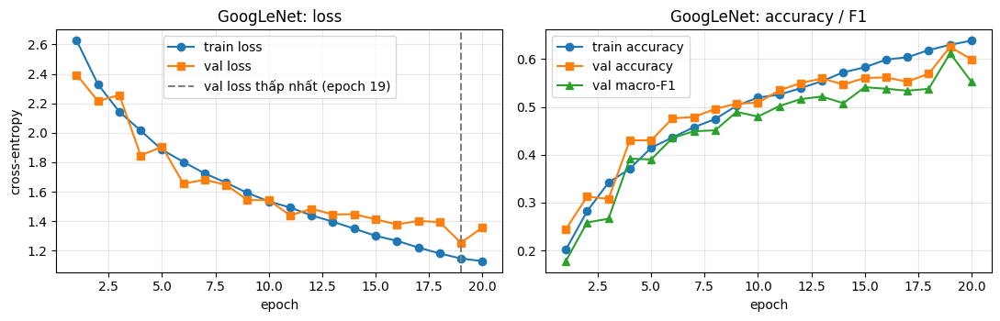

GoogLeNet trên tập test
Accuracy       : 0.5221
Precision macro: 0.5516
Recall macro   : 0.5070
F1 macro       : 0.5173

                  precision    recall  f1-score   support

        banh-can     0.5641    0.4564    0.5046       241
        banh-hoi     0.5952    0.5667    0.5806       607
    banh-mi-chao     0.6223    0.5986    0.6102       289
        banh-tet     0.8731    0.4725    0.6132       364
 banh-trang-tron     0.6084    0.3269    0.4253       309
          banh-u     0.5950    0.4091    0.4848       176
        banh-uot     0.3984    0.5179    0.4503       560
       bap-nuong     0.4132    0.3497    0.3788       143
          bo-kho     0.5205    0.6391    0.5737       338
       bo-la-lot     0.5259    0.7751    0.6267       458
       bot-chien     0.3506    0.5652    0.4327       276
           ca-ri     0.4252    0.3158    0.3624       171
    canh-kho-qua     0.7432    0.6586    0.6984       290
   canh-khoai-mo     0.8378    0.7828    0.8094       198
        

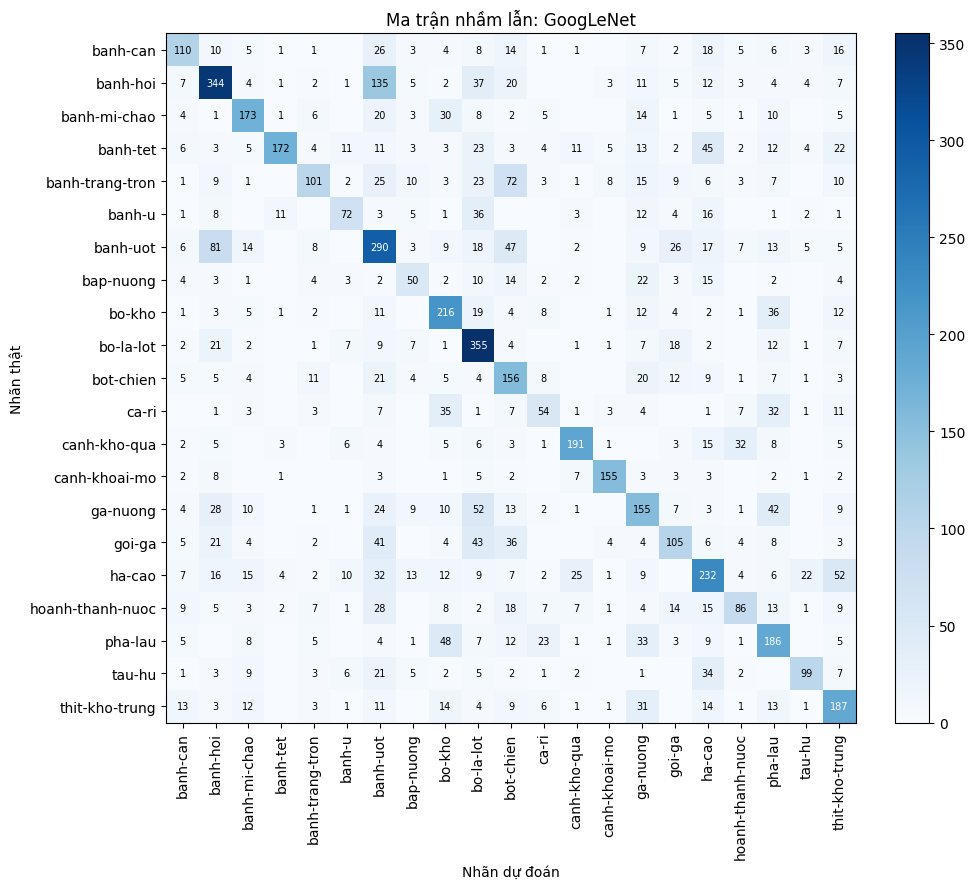

5 cặp (thật -> đoán) nhầm nhiều nhất:
  banh-hoi -> banh-uot: 135 ảnh
  banh-uot -> banh-hoi: 81 ảnh
  banh-trang-tron -> bot-chien: 72 ảnh
  ga-nuong -> bo-la-lot: 52 ảnh
  ha-cao -> thit-kho-trung: 52 ảnh


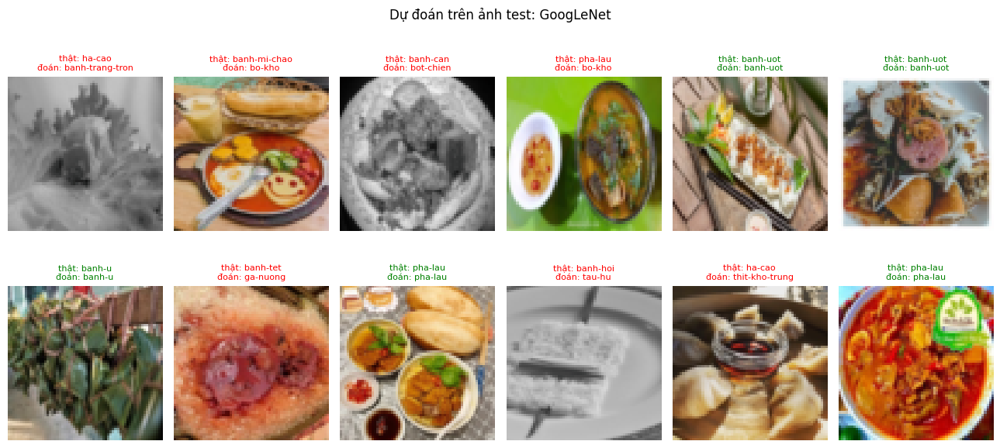

In [11]:
EPOCHS_GOOGLENET = 20 if GPU else 15

set_seed()
googlenet = GoogLeNet(len(CLASSES))
hist_gn = fit(googlenet, loaders64, epochs=EPOCHS_GOOGLENET)
report(googlenet, hist_gn, loaders64, "GoogLeNet")

In [12]:
pd.DataFrame(RESULTS).T.loc[["LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet"],
                             ["Tham số", "Giây/epoch", "Accuracy", "F1-macro"]]

,Tham số,Giây/epoch,Accuracy,F1-macro
LeNet-5 (AvgPool),339421.0,7.885023,0.298563,0.274861
LeNet-5 (MaxPool),339421.0,7.794411,0.312032,0.286308
GoogLeNet,1065749.0,9.122559,0.522149,0.517314


**Nhận xét Bài 2.**
- Số channel ra của ba Inception block khớp với tính tay: 256, 480, 512.
- GoogLeNet rút gọn có 1,065,749 tham số (gấp ~3.1 lần LeNet), đạt F1-macro 0.5173 và accuracy 0.5221, gần gấp đôi LeNet. Thời gian mỗi epoch chỉ tăng nhẹ (9.1 s so với 7.8 s trên GPU).
- Lý do tốt hơn:
  - Mỗi Inception block học đặc trưng ở nhiều kích thước cùng lúc (1×1, 3×3, 5×5, pooling).
  - Conv 1×1 giảm channel giúp mạng sâu hơn mà vẫn ít tham số.
  - Global average pooling giữ lớp phân loại chỉ còn 10,773 tham số.
  - BatchNorm giúp hội tụ nhanh.
- Lỗi chủ yếu là cặp `banh-hoi ↔ banh-uot` (135 + 81 ảnh). Cả hai là bánh từ bột gạo màu trắng, hình dạng gần giống nhau. Tiếp theo là `banh-trang-tron → bot-chien` (72 ảnh).
- Val F1 vẫn còn dao động và tăng ở các epoch cuối, nên huấn luyện thêm có thể cải thiện tiếp.

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

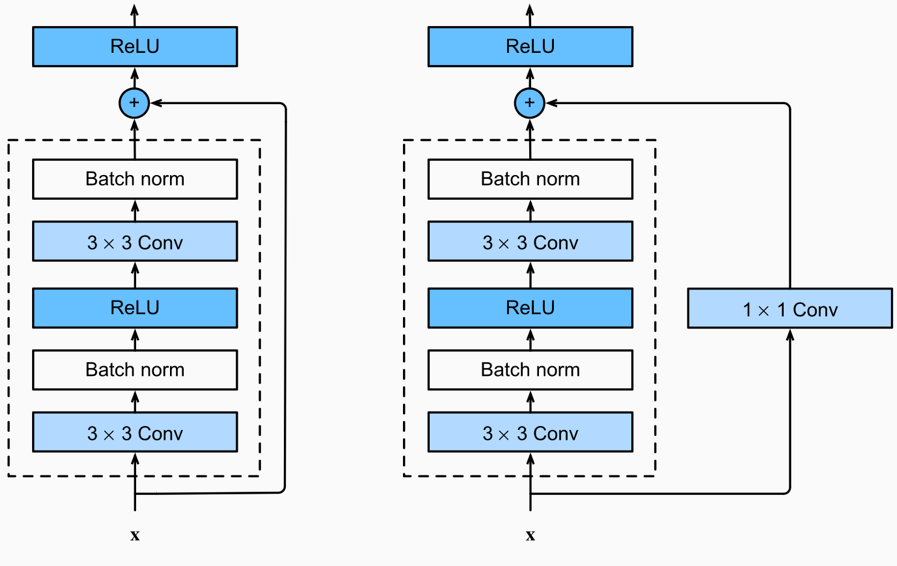

**ResNet**

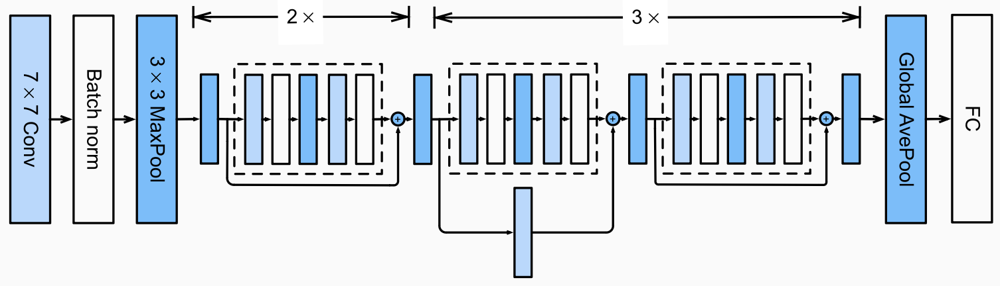

In [13]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))


class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, 1)
        self.layer2 = self._stage(64, 128, 2)
        self.layer3 = self._stage(128, 256, 2)
        self.layer4 = self._stage(256, 512, 2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride), BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))


r18 = ResNet18(len(CLASSES))
x = torch.zeros(1, 3, 96, 96)
print(f"{'stage':<10}{'output shape':<20}{'tham số':>12}")
x = r18.stem(x)
print(f"{'stem':<10}{str(tuple(x.shape)):<20}{n_params(r18.stem):>12,}")
for name in ("layer1", "layer2", "layer3", "layer4"):
    x = getattr(r18, name)(x)
    print(f"{name:<10}{str(tuple(x.shape)):<20}{n_params(getattr(r18, name)):>12,}")
print(f"{'fc':<10}{str((1, len(CLASSES))):<20}{n_params(r18.fc):>12,}")
print(f"{'TỔNG':<10}{'':<20}{n_params(r18):>12,}")

stage     output shape             tham số
stem      (1, 64, 24, 24)            9,536
layer1    (1, 64, 24, 24)          147,968
layer2    (1, 128, 12, 12)         525,568
layer3    (1, 256, 6, 6)         2,099,712
layer4    (1, 512, 3, 3)         8,393,728
fc        (1, 21)                   10,773
TỔNG                            11,187,285


epoch  1  train 2.7414/0.1761   val 2.6470/0.2440  F1 0.1597  12s  *
epoch  2  train 2.4788/0.2417   val 2.3369/0.2769  F1 0.2237  12s  *
epoch  3  train 2.3502/0.2816   val 2.3246/0.2769  F1 0.2134  12s
epoch  4  train 2.2303/0.3132   val 2.2364/0.3028  F1 0.2773  12s  *
epoch  5  train 2.1317/0.3435   val 2.0493/0.3715  F1 0.3420  12s  *
epoch  6  train 2.0205/0.3679   val 1.9700/0.3884  F1 0.3457  12s  *
epoch  7  train 1.9384/0.3909   val 2.0462/0.3805  F1 0.3295  12s
epoch  8  train 1.8675/0.4100   val 1.8635/0.4124  F1 0.3683  12s  *
epoch  9  train 1.7822/0.4410   val 1.8162/0.4392  F1 0.4069  12s  *
epoch 10  train 1.6911/0.4676   val 1.6804/0.4592  F1 0.4267  12s  *
epoch 11  train 1.6301/0.4853   val 1.7451/0.4851  F1 0.4473  12s  *
epoch 12  train 1.5598/0.5115   val 1.6280/0.4960  F1 0.4507  12s  *
epoch 13  train 1.5096/0.5232   val 1.6252/0.4691  F1 0.4451  12s
epoch 14  train 1.4474/0.5324   val 1.4554/0.5637  F1 0.5304  12s  *
epoch 15  train 1.3962/0.5573   val 1.6015/

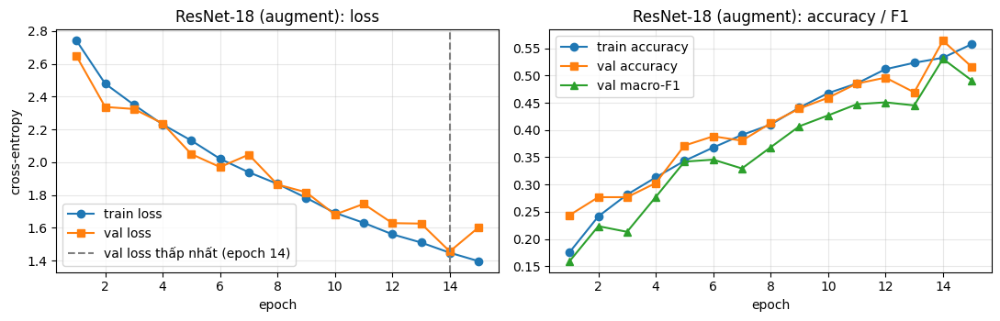

ResNet-18 (augment) trên tập test
Accuracy       : 0.4771
Precision macro: 0.4930
Recall macro   : 0.4585
F1 macro       : 0.4533

                  precision    recall  f1-score   support

        banh-can     0.3780    0.4564    0.4135       241
        banh-hoi     0.5862    0.5041    0.5421       607
    banh-mi-chao     0.4150    0.6505    0.5067       289
        banh-tet     0.8547    0.4038    0.5485       364
 banh-trang-tron     0.3925    0.1359    0.2019       309
          banh-u     0.5270    0.2216    0.3120       176
        banh-uot     0.4129    0.4786    0.4433       560
       bap-nuong     0.3402    0.2308    0.2750       143
          bo-kho     0.3948    0.5444    0.4577       338
       bo-la-lot     0.5140    0.7991    0.6256       458
       bot-chien     0.3222    0.5616    0.4095       276
           ca-ri     0.3718    0.1696    0.2329       171
    canh-kho-qua     0.6500    0.6276    0.6386       290
   canh-khoai-mo     0.8957    0.7374    0.8089       19

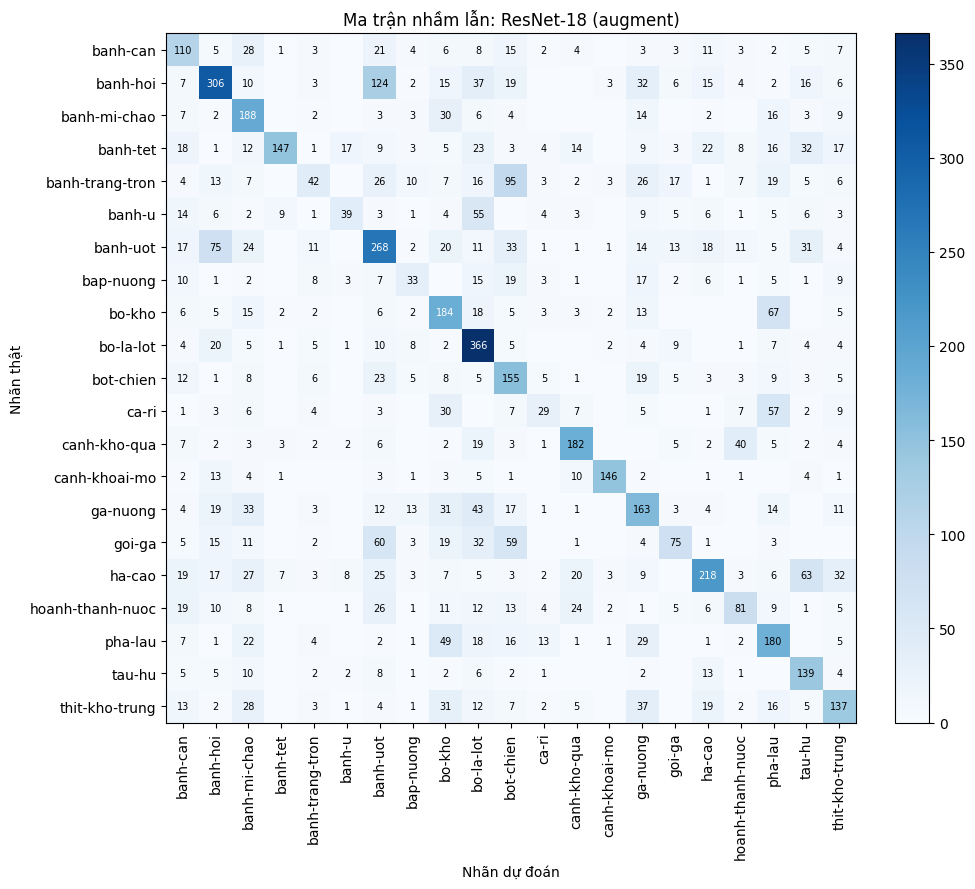

5 cặp (thật -> đoán) nhầm nhiều nhất:
  banh-hoi -> banh-uot: 124 ảnh
  banh-trang-tron -> bot-chien: 95 ảnh
  banh-uot -> banh-hoi: 75 ảnh
  bo-kho -> pha-lau: 67 ảnh
  ha-cao -> tau-hu: 63 ảnh


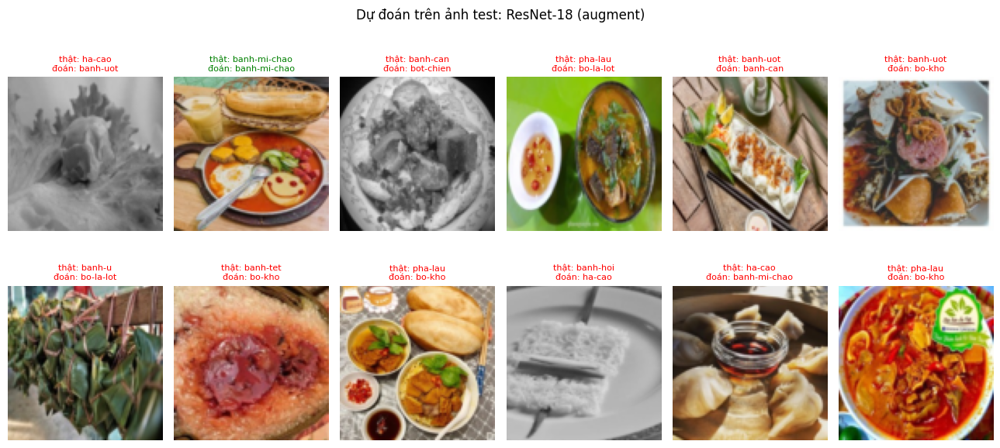

In [14]:
EPOCHS_R18 = 15 if GPU else 10
loaders96_aug = build_loaders(96, augment=True)
loaders96_noaug = build_loaders(96, augment=False)

set_seed()
r18_aug = ResNet18(len(CLASSES))
hist_r18_aug = fit(r18_aug, loaders96_aug, epochs=EPOCHS_R18)
report(r18_aug, hist_r18_aug, loaders96_aug, "ResNet-18 (augment)")

epoch  1  train 2.6762/0.1917   val 2.6600/0.2022  F1 0.1323  10s  *
epoch  2  train 2.3502/0.2733   val 2.2108/0.3098  F1 0.2593  10s  *
epoch  3  train 2.1602/0.3296   val 2.1161/0.3376  F1 0.2733  9s  *
epoch  4  train 1.9734/0.3884   val 2.0123/0.3685  F1 0.3320  10s  *
epoch  5  train 1.8015/0.4352   val 2.0304/0.3715  F1 0.3327  10s  *
epoch  6  train 1.6015/0.4957   val 2.0057/0.3795  F1 0.3388  10s  *
epoch  7  train 1.4021/0.5565   val 1.9498/0.4243  F1 0.3915  10s  *
epoch  8  train 1.1545/0.6277   val 1.8460/0.4522  F1 0.4172  9s  *
epoch  9  train 0.8496/0.7238   val 2.0449/0.4552  F1 0.4318  10s  *
epoch 10  train 0.5611/0.8143   val 1.9552/0.4960  F1 0.4664  10s  *
epoch 11  train 0.3389/0.8877   val 2.2887/0.5020  F1 0.4669  10s  *
epoch 12  train 0.2340/0.9243   val 2.5155/0.5030  F1 0.4652  10s
epoch 13  train 0.1853/0.9404   val 2.4564/0.5000  F1 0.4845  9s  *
epoch 14  train 0.1327/0.9560   val 2.4440/0.5149  F1 0.4923  10s  *
epoch 15  train 0.1202/0.9625   val 2.61

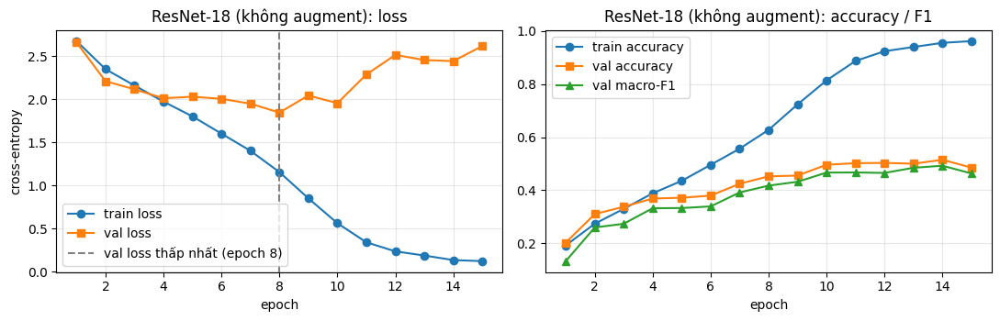

ResNet-18 (không augment) trên tập test
Accuracy       : 0.4193
Precision macro: 0.4255
Recall macro   : 0.4102
F1 macro       : 0.4012

                  precision    recall  f1-score   support

        banh-can     0.3790    0.1950    0.2575       241
        banh-hoi     0.5112    0.5255    0.5183       607
    banh-mi-chao     0.4685    0.4118    0.4383       289
        banh-tet     0.5388    0.3819    0.4469       364
 banh-trang-tron     0.3205    0.2427    0.2762       309
          banh-u     0.2948    0.2898    0.2923       176
        banh-uot     0.5195    0.2143    0.3034       560
       bap-nuong     0.1813    0.2308    0.2031       143
          bo-kho     0.5793    0.2811    0.3785       338
       bo-la-lot     0.4131    0.7162    0.5240       458
       bot-chien     0.3702    0.2428    0.2932       276
           ca-ri     0.2513    0.2749    0.2626       171
    canh-kho-qua     0.4625    0.6172    0.5288       290
   canh-khoai-mo     0.8609    0.6566    0.7450   

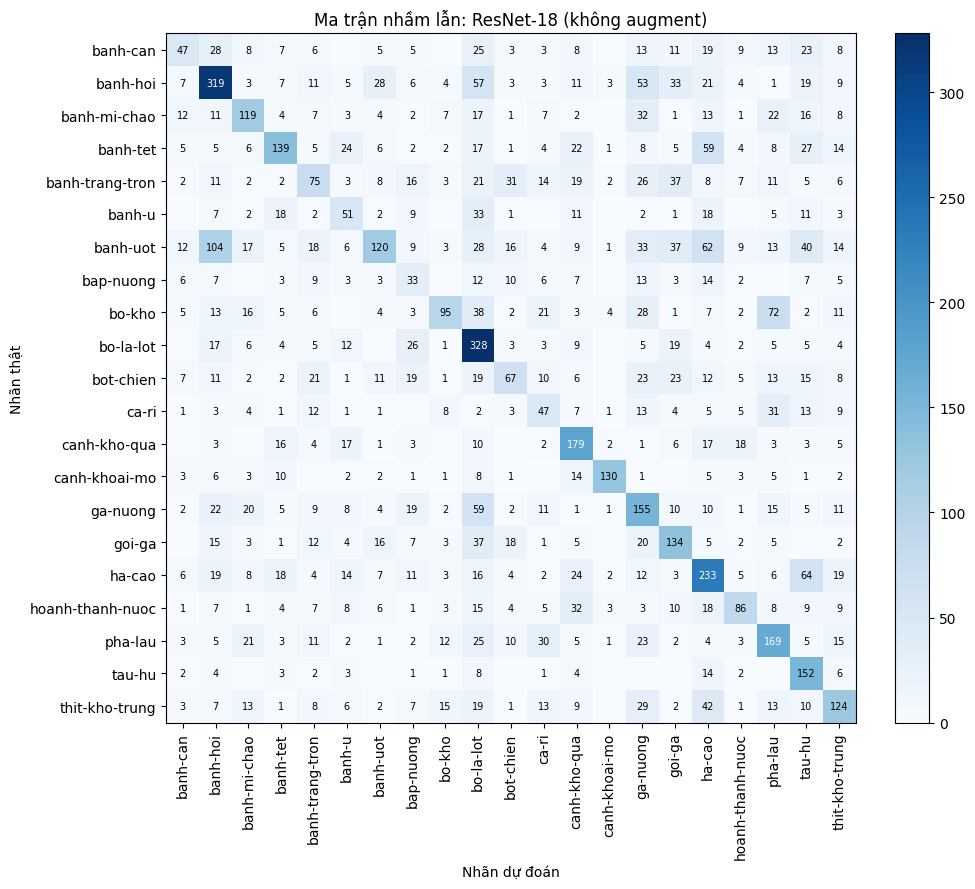

5 cặp (thật -> đoán) nhầm nhiều nhất:
  banh-uot -> banh-hoi: 104 ảnh
  bo-kho -> pha-lau: 72 ảnh
  ha-cao -> tau-hu: 64 ảnh
  banh-uot -> ha-cao: 62 ảnh
  banh-tet -> ha-cao: 59 ảnh


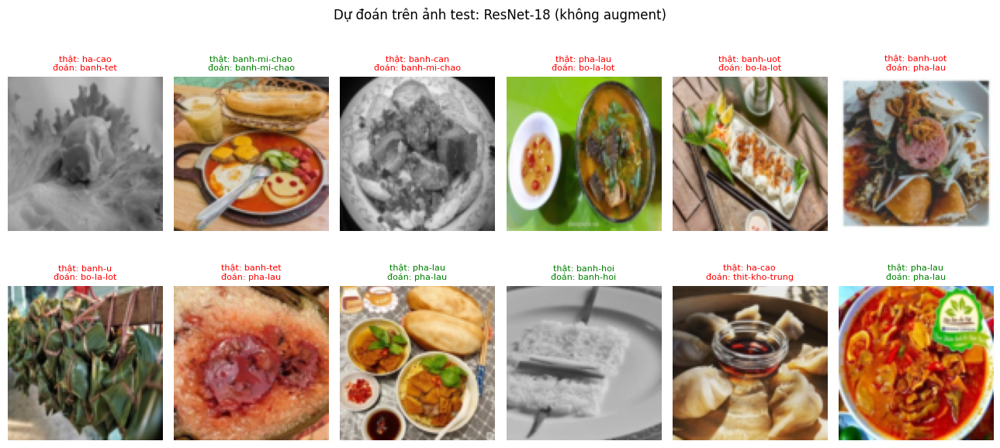

In [15]:
set_seed()
r18_noaug = ResNet18(len(CLASSES))
hist_r18_noaug = fit(r18_noaug, loaders96_noaug, epochs=EPOCHS_R18)
report(r18_noaug, hist_r18_noaug, loaders96_noaug, "ResNet-18 (không augment)")

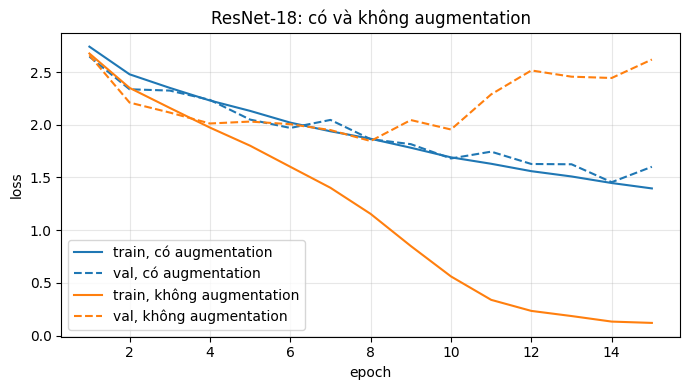

macro-F1 có augment   : 0.4533
macro-F1 không augment: 0.4012
chênh lệch            : +0.0522


In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
for h, name, c in [(hist_r18_aug, "có augmentation", "C0"), (hist_r18_noaug, "không augmentation", "C1")]:
    ep = range(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], "-", c=c, label=f"train, {name}")
    ax.plot(ep, h["val_loss"], "--", c=c, label=f"val, {name}")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("ResNet-18: có và không augmentation")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

f1_aug = RESULTS["ResNet-18 (augment)"]["F1-macro"]
f1_noaug = RESULTS["ResNet-18 (không augment)"]["F1-macro"]
print(f"macro-F1 có augment   : {f1_aug:.4f}")
print(f"macro-F1 không augment: {f1_noaug:.4f}")
print(f"chênh lệch            : {f1_aug - f1_noaug:+.4f}")

**Nhận xét Bài 3.**
- ResNet-18 có 11,187,285 tham số (gấp 33 lần LeNet), huấn luyện từ đầu với ảnh 96×96 trong 15 epoch.
- **Không augmentation:** train loss giảm về 0.12 (train accuracy 0.96), trong khi val loss chạm đáy ở **epoch 8** (1.85) rồi tăng lên 2.62. Hai đường bắt đầu tách nhau từ epoch 8–9, tức overfitting rõ rệt. F1-macro trên test là 0.4012.
- **Có augmentation:** train loss và val loss giảm cùng nhau, không thấy tách rõ, nên overfitting được kiềm chế. F1-macro đạt 0.4533, cao hơn **+0.0522**.
- ResNet-18 vẫn thấp hơn GoogLeNet (0.5173), dù không có nghĩa là cài sai: 11 triệu tham số nhưng chỉ có khoảng 9 nghìn ảnh train và 15 epoch là chưa đủ để hội tụ (val F1 của bản có augmentation vẫn đang tăng). Muốn cải thiện thì cần thêm epoch, thêm dữ liệu, hoặc dùng trọng số pretrained (Bài 4).

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

Feature extraction tính đặc trưng của backbone đóng băng một lần rồi chỉ huấn luyện lớp phân loại. Trên GPU: ảnh 224×224, fine-tuning 5 epoch; khi chỉ có CPU, notebook tự giảm còn ảnh 160×160 và fine-tuning 1 epoch để kịp thời gian.

In [17]:
from transformers import ResNetForImageClassification


class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes)
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            self.resnet.requires_grad_(False)

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.resnet.eval()
        return self

    def forward(self, images):
        features = self.resnet(images).pooler_output.flatten(1)
        return self.classifier(features)

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Tham số: 23,551,061 | được cập nhật: 43,029
trích đặc trưng 2048 chiều cho 16,726 ảnh trong 60s
epoch  1  train 2.0407/0.4840   val 1.5068/0.6783  F1 0.6634  0s  *
epoch  2  train 1.2802/0.6958   val 1.1654/0.7112  F1 0.7084  0s  *
epoch  3  train 1.0199/0.7438   val 1.0132/0.7361  F1 0.7287  0s  *
epoch  4  train 0.8751/0.7743   val 0.9052/0.7719  F1 0.7658  0s  *
epoch  5  train 0.7762/0.7996   val 0.8419/0.7759  F1 0.7689  0s  *
epoch  6  train 0.7021/0.8200   val 0.7981/0.7759  F1 0.7665  0s
epoch  7  train 0.6461/0.8342   val 0.7578/0.7978  F1 0.7914  1s  *
epoch  8  train 0.5956/0.8528   val 0.7324/0.8028  F1 0.8023  0s  *
epoch  9  train 0.5548/0.8580   val 0.7098/0.8028  F1 0.8021  0s
epoch 10  train 0.5208/0.8712   val 0.6900/0.8137  F1 0.8101  0s  *
epoch 11  train 0.4883/0.8804   val 0.6708/0.8157  F1 0.8122  0s  *
epoch 12  train 0.4609/0.8876   val 0.6581/0.8147  F1 0.8108  0s
epoch 13  train 0.4358/0.8949   val 0.6469/0.8207  F1 0.8160  0s  *
epoch 14  train 0.4128/0.9009

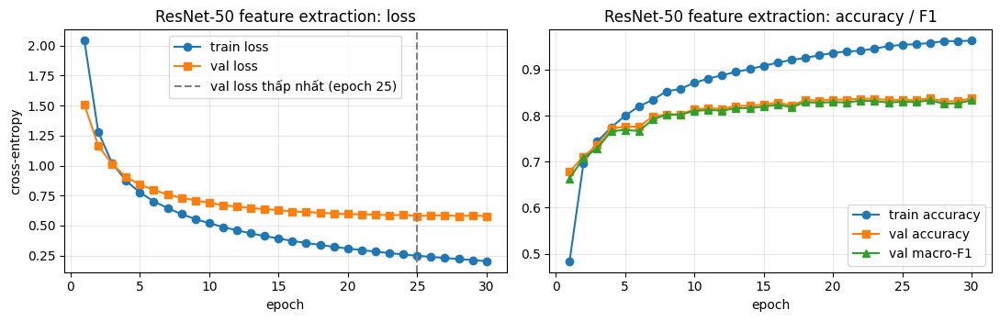

ResNet-50 feature extraction trên tập test
Accuracy       : 0.7683
Precision macro: 0.7853
Recall macro   : 0.7717
F1 macro       : 0.7753

                  precision    recall  f1-score   support

        banh-can     0.7778    0.8133    0.7951       241
        banh-hoi     0.6464    0.8072    0.7179       607
    banh-mi-chao     0.7761    0.8997    0.8333       289
        banh-tet     0.9371    0.7775    0.8498       364
 banh-trang-tron     0.8618    0.7670    0.8116       309
          banh-u     0.7621    0.8920    0.8220       176
        banh-uot     0.6447    0.6643    0.6544       560
       bap-nuong     0.9925    0.9231    0.9565       143
          bo-kho     0.6785    0.7367    0.7064       338
       bo-la-lot     0.8555    0.8013    0.8275       458
       bot-chien     0.7238    0.7500    0.7367       276
           ca-ri     0.5345    0.3626    0.4321       171
    canh-kho-qua     0.8333    0.8448    0.8390       290
   canh-khoai-mo     0.9176    0.8434    0.8789

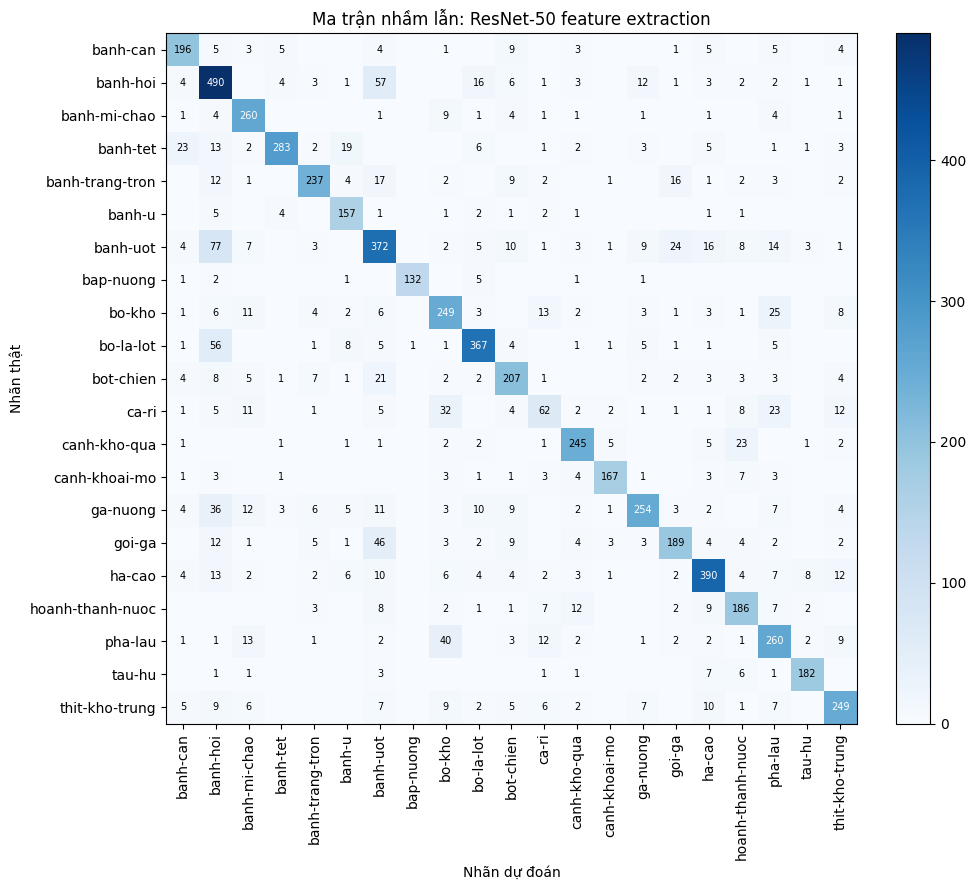

5 cặp (thật -> đoán) nhầm nhiều nhất:
  banh-uot -> banh-hoi: 77 ảnh
  banh-hoi -> banh-uot: 57 ảnh
  bo-la-lot -> banh-hoi: 56 ảnh
  goi-ga -> banh-uot: 46 ảnh
  pha-lau -> bo-kho: 40 ảnh


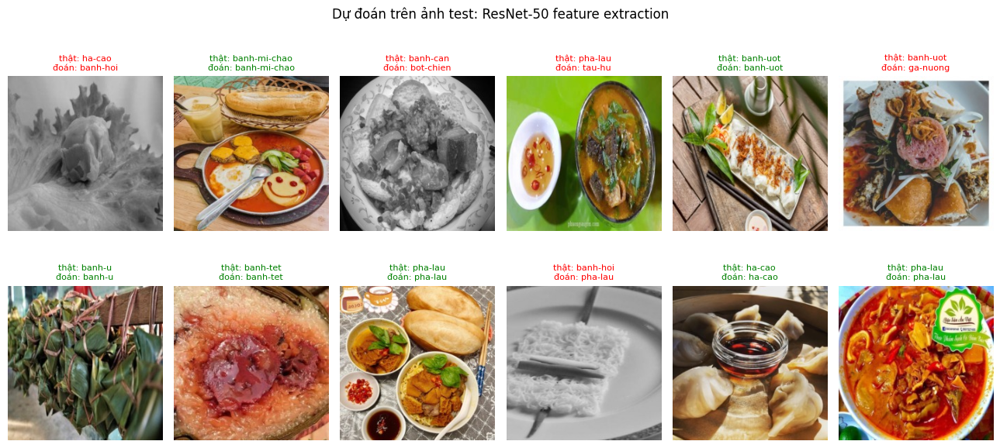

In [18]:
EPOCHS_FE = 30
R50_SIZE = CACHE_SIZE
loaders_r50 = build_loaders(R50_SIZE, augment=False)

set_seed()
r50_fe = PretrainedResnet(len(CLASSES), freeze_backbone=True).to(device).eval()
print(f"Tham số: {n_params(r50_fe):,} | được cập nhật: {n_params(r50_fe, True):,}")


@torch.no_grad()
def extract_features(backbone, loader):
    feats, ys = [], []
    for xb, yb in loader:
        feats.append(backbone(xb.to(device)).pooler_output.flatten(1).cpu())
        ys.append(yb)
    return TensorDataset(torch.cat(feats), torch.cat(ys))


t0 = time.time()
feat_ds = [extract_features(r50_fe.resnet, dl) for dl in loaders_r50]
print(f"trích đặc trưng 2048 chiều cho {sum(len(d) for d in feat_ds):,} ảnh trong {time.time() - t0:.0f}s")
feat_loaders = (DataLoader(feat_ds[0], batch_size=BATCH, shuffle=True),
                DataLoader(feat_ds[1], batch_size=256), DataLoader(feat_ds[2], batch_size=256))

hist_fe = fit(r50_fe.classifier, feat_loaders, epochs=EPOCHS_FE, lr=1e-3)
report(r50_fe.classifier, hist_fe, feat_loaders, "ResNet-50 feature extraction",
       preview=(r50_fe, loaders_r50[2].dataset))
RESULTS["ResNet-50 feature extraction"]["Tham số"] = n_params(r50_fe)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Tham số: 23,551,061 | được cập nhật: 23,551,061
epoch  1  train 2.7688/0.1654   val 2.3483/0.4133  F1 0.3087  98s  *
epoch  2  train 1.7144/0.5398   val 1.1378/0.6673  F1 0.6454  97s  *
epoch  3  train 1.0051/0.7103   val 0.7785/0.7649  F1 0.7532  97s  *
epoch  4  train 0.7423/0.7679   val 0.6195/0.8058  F1 0.7921  97s  *
epoch  5  train 0.5905/0.8168   val 0.5529/0.8277  F1 0.8224  97s  *
Dùng trọng số ở epoch có val macro-F1 cao nhất: 0.8224


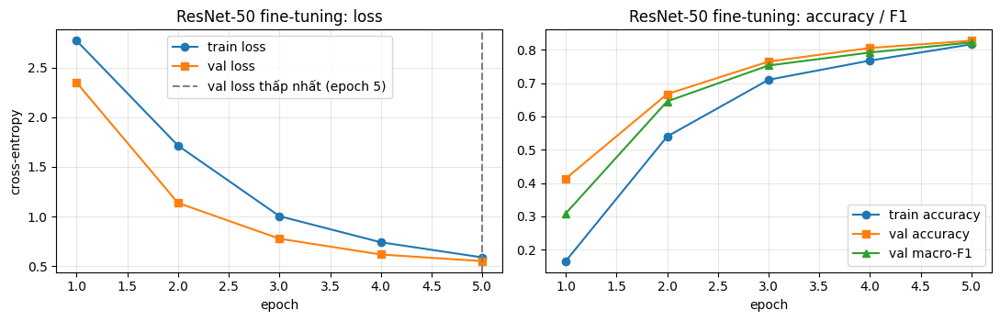

ResNet-50 fine-tuning trên tập test
Accuracy       : 0.7779
Precision macro: 0.8029
Recall macro   : 0.7745
F1 macro       : 0.7750

                  precision    recall  f1-score   support

        banh-can     0.7860    0.8382    0.8112       241
        banh-hoi     0.8640    0.7117    0.7805       607
    banh-mi-chao     0.8537    0.8685    0.8611       289
        banh-tet     0.9635    0.7253    0.8276       364
 banh-trang-tron     0.9102    0.7217    0.8051       309
          banh-u     0.7032    0.8750    0.7797       176
        banh-uot     0.7048    0.7036    0.7042       560
       bap-nuong     0.9301    0.9301    0.9301       143
          bo-kho     0.5624    0.8136    0.6651       338
       bo-la-lot     0.8125    0.9367    0.8702       458
       bot-chien     0.8692    0.6739    0.7592       276
           ca-ri     0.7609    0.2047    0.3226       171
    canh-kho-qua     0.9255    0.9000    0.9126       290
   canh-khoai-mo     0.9651    0.8384    0.8973       

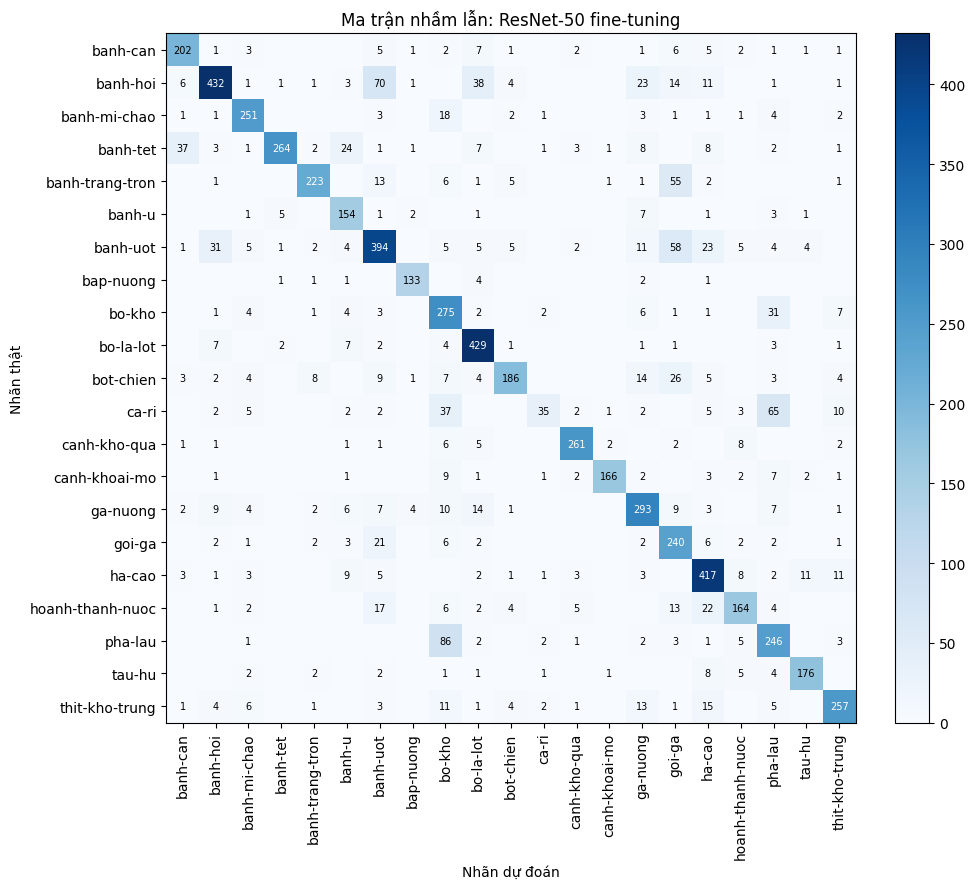

5 cặp (thật -> đoán) nhầm nhiều nhất:
  pha-lau -> bo-kho: 86 ảnh
  banh-hoi -> banh-uot: 70 ảnh
  ca-ri -> pha-lau: 65 ảnh
  banh-uot -> goi-ga: 58 ảnh
  banh-trang-tron -> goi-ga: 55 ảnh


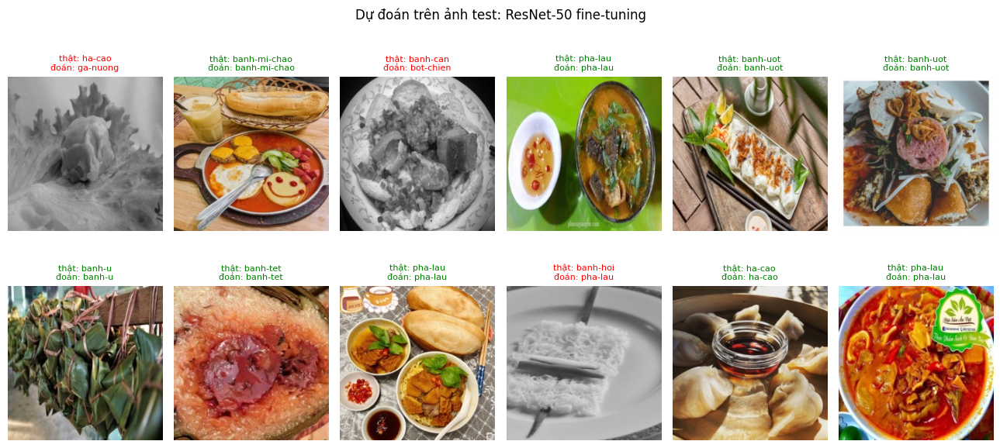

In [19]:
EPOCHS_FT = 5 if GPU else 1

set_seed()
r50_ft = PretrainedResnet(len(CLASSES), freeze_backbone=False)
print(f"Tham số: {n_params(r50_ft):,} | được cập nhật: {n_params(r50_ft, True):,}")
hist_ft = fit(r50_ft, build_loaders(R50_SIZE), epochs=EPOCHS_FT, lr=1e-4)
report(r50_ft, hist_ft, loaders_r50, "ResNet-50 fine-tuning")

**Nhận xét Bài 4.**
- **Feature extraction:** chỉ học 43,029 tham số của lớp phân loại. Đặc trưng 2048 chiều được trích một lần (60 s trên GPU), nên mỗi epoch train lớp cuối mất chưa tới 1 s. Kết quả: F1-macro 0.7753, accuracy 0.7683.
- **Fine-tuning** (lr 1e-4, 5 epoch, mỗi epoch ~97 s): F1-macro 0.7750, accuracy 0.7779 và precision cao nhất (0.8029). Val F1 vẫn đang tăng (0.79 → 0.82 ở hai epoch cuối), nên thêm epoch nhiều khả năng sẽ vượt feature extraction.
- **So với ResNet-18 train từ đầu (Bài 3, F1 0.4533), transfer learning tăng F1-macro thêm khoảng 0.32.** Backbone đã học đặc trưng tổng quát (cạnh, vân, hình dạng, màu sắc) từ 1.2 triệu ảnh ImageNet, nên chỉ cần khoảng 9 nghìn ảnh để thích nghi với món ăn Việt. Mô hình train từ đầu phải tự học mọi thứ từ khoảng 9 nghìn ảnh.
- Lớp khó nhất ở cả hai chế độ là `ca-ri` (F1 0.32–0.43), hay bị nhầm với `pha-lau` và `bo-kho`, đều là món có nước sốt màu nâu đỏ. Cặp `banh-hoi ↔ banh-uot` vẫn là nguồn nhầm lẫn chính.

### Bảng tổng hợp kết quả

In [20]:
summary = pd.DataFrame(RESULTS).T
summary.index.name = "Mô hình"
summary.style.format({"Tham số": "{:,}", "Tham số học": "{:,}", "Giây/epoch": "{:.1f}",
                      "Accuracy": "{:.4f}", "Precision": "{:.4f}",
                      "Recall": "{:.4f}", "F1-macro": "{:.4f}"})

,Tham số,Tham số học,Giây/epoch,Accuracy,Precision,Recall,F1-macro
Mô hình,,,,,,,
LeNet-5 (AvgPool),"339,421.0","339,421.0",7.9,0.2986,0.3011,0.2805,0.2749
LeNet-5 (MaxPool),"339,421.0","339,421.0",7.8,0.3120,0.3247,0.2853,0.2863
GoogLeNet,"1,065,749.0","1,065,749.0",9.1,0.5221,0.5516,0.5070,0.5173
ResNet-18 (augment),"11,187,285.0","11,187,285.0",11.9,0.4771,0.4930,0.4585,0.4533
ResNet-18 (không augment),"11,187,285.0","11,187,285.0",9.5,0.4193,0.4255,0.4102,0.4012
ResNet-50 feature extraction,"23,551,061.0","43,029.0",0.5,0.7683,0.7853,0.7717,0.7753
ResNet-50 fine-tuning,"23,551,061.0","23,551,061.0",97.4,0.7779,0.8029,0.7745,0.7750


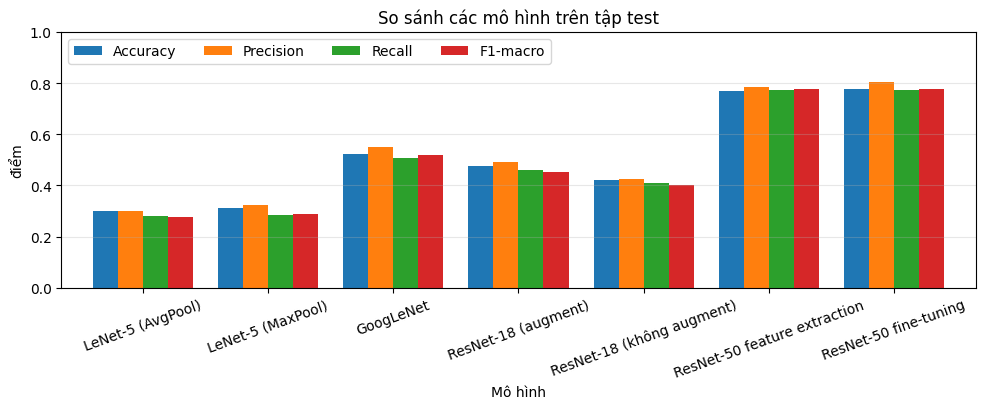

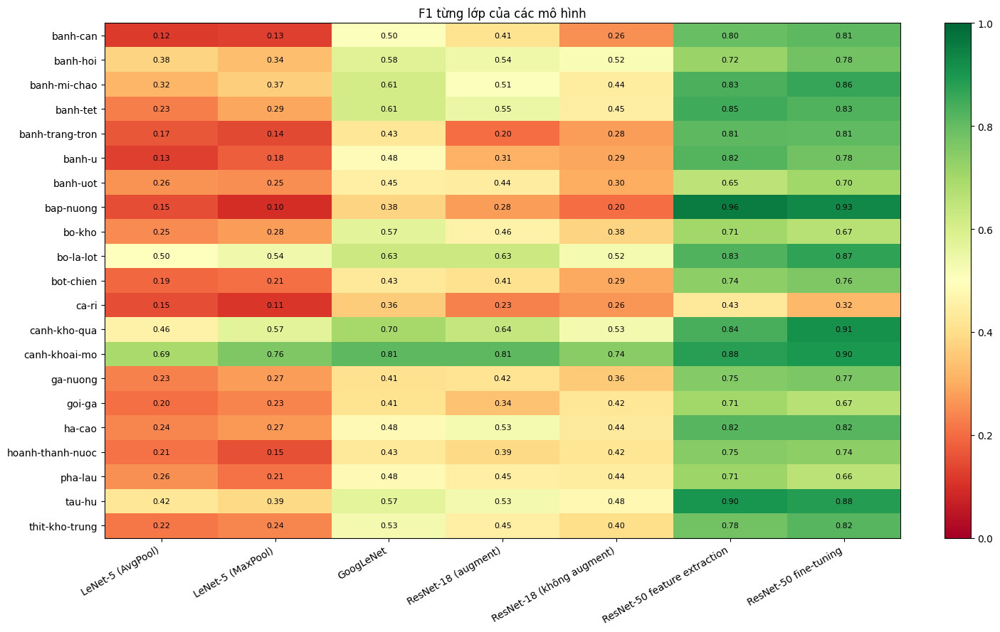

In [21]:
summary[["Accuracy", "Precision", "Recall", "F1-macro"]].astype(float).plot.bar(
    figsize=(10, 4.2), rot=20, ylim=(0, 1), width=0.8)
plt.title("So sánh các mô hình trên tập test"); plt.ylabel("điểm")
plt.grid(axis="y", alpha=.3); plt.legend(ncol=4, loc="upper left"); plt.tight_layout(); plt.show()

f1_table = pd.DataFrame(PER_CLASS_F1, index=CLASSES)
fig, ax = plt.subplots(figsize=(1.6 * f1_table.shape[1] + 3, 9))
im = ax.imshow(f1_table.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(f1_table.shape[1]), f1_table.columns, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i, j in np.ndindex(f1_table.shape):
    ax.text(j, i, f"{f1_table.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("F1 từng lớp của các mô hình")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

**Kết luận.** Notebook được chạy trên Kaggle (GPU).

Xếp hạng theo F1-macro trên tập test:

| # | Mô hình | F1-macro |
|---|---|---|
| 1 | ResNet-50 feature extraction | 0.7753 |
| 2 | ResNet-50 fine-tuning | 0.7750 |
| 3 | GoogLeNet | 0.5173 |
| 4 | ResNet-18 (có augment) | 0.4533 |
| 5 | ResNet-18 (không augment) | 0.4012 |
| 6 | LeNet-5 (MaxPool) | 0.2863 |
| 7 | LeNet-5 (AvgPool) | 0.2749 |

- Với tập dữ liệu nhỏ (khoảng 10 nghìn ảnh train), transfer learning từ mô hình pretrained là lựa chọn tốt nhất.
- Trong các mô hình train từ đầu, kiến trúc gọn có BatchNorm và global average pooling (GoogLeNet) hiệu quả hơn mạng rất sâu, nhiều tham số (ResNet-18).
- Data augmentation giúp giảm overfitting rõ rệt khi train từ đầu.
- Các món có hình thức giống nhau (bánh hỏi / bánh ướt, cà ri / phá lấu / bò kho) là nguồn nhầm lẫn chính ở mọi mô hình.